# Import
- Import các thư viện
- Đọc dataset

In [47]:
import shutil

shutil.rmtree('/kaggle/working/output', ignore_errors=True)
print("Đã xoá thư mục output")

Đã xoá thư mục output


In [48]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
from PIL import Image
import os
import cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [49]:
import pandas as pd

abnormal = pd.read_excel('/kaggle/input/datasets/dangthithuha/anomaly-64-phanloai/DataVOC_New_2025_Anomaly_64_anh_phanloai.xlsx')
normal = pd.read_excel('/kaggle/input/datasets/dangthithuha/voc-normal-452/DataVOC_New_2025_Nomal_chuan_452.xlsx')

# Thêm nhãn
abnormal['is_normal'] = 0
normal['is_normal'] = 1

# Đổi tên cột cho giống nhau
normal = normal.rename(columns={
    'Date': 'Ngay',
    'Time': 'Thoigian'
})

# Lấy union tất cả cột
all_cols = sorted(set(abnormal.columns) | set(normal.columns))

# Thêm cột thiếu
for col in all_cols:
    if col not in abnormal.columns:
        abnormal[col] = None
    if col not in normal.columns:
        normal[col] = None

# Sắp xếp lại thứ tự cột
abnormal = abnormal[all_cols]
normal = normal[all_cols]

print(abnormal.head())
print(normal.head())

   Acetone       Anomaly    CH1  CH10    CH2    CH3    CH4    CH5   CH6  \
0        0  Sensor drift  1.000   1.0  1.025  0.996  1.000  0.932  1.08   
1        0  Sensor drift  1.000   1.0  1.025  0.998  1.009  0.925  1.00   
2        0  Sensor drift  1.006   1.0  1.012  1.004  1.009  0.918  1.00   
3        0  Sensor drift  1.006   1.0  1.037  1.009  1.009  0.918  1.00   
4        0  Sensor drift  1.012   1.0  1.012  1.016  1.000  0.907  1.04   

     CH7  ...  Class       Date Ethanol Methanol  Ngay  STT Sample  Thoigian  \
0  0.991  ...   None 2023-10-30      50        0  None    1      1      None   
1  0.991  ...   None 2023-10-30      50        0  None    2      1      None   
2  0.991  ...   None 2023-10-30      50        0  None    3      1      None   
3  0.988  ...   None 2023-10-30      50        0  None    4      1      None   
4  0.988  ...   None 2023-10-30      50        0  None    5      1      None   

       Time is_normal  
0  07:45:08         0  
1  07:45:10         

In [50]:
# Merge
df = pd.concat([abnormal, normal], ignore_index=True)
print(df.shape)
print(df.head())

(49020, 22)
   Acetone       Anomaly    CH1  CH10    CH2    CH3    CH4    CH5   CH6  \
0        0  Sensor drift  1.000   1.0  1.025  0.996  1.000  0.932  1.08   
1        0  Sensor drift  1.000   1.0  1.025  0.998  1.009  0.925  1.00   
2        0  Sensor drift  1.006   1.0  1.012  1.004  1.009  0.918  1.00   
3        0  Sensor drift  1.006   1.0  1.037  1.009  1.009  0.918  1.00   
4        0  Sensor drift  1.012   1.0  1.012  1.016  1.000  0.907  1.04   

     CH7  ...  Class       Date Ethanol Methanol Ngay  STT Sample  Thoigian  \
0  0.991  ...   None 2023-10-30      50        0  NaT    1      1      None   
1  0.991  ...   None 2023-10-30      50        0  NaT    2      1      None   
2  0.991  ...   None 2023-10-30      50        0  NaT    3      1      None   
3  0.988  ...   None 2023-10-30      50        0  NaT    4      1      None   
4  0.988  ...   None 2023-10-30      50        0  NaT    5      1      None   

       Time is_normal  
0  07:45:08         0  
1  07:45:10   

/tmp/ipykernel_58/2342380570.py:2: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([abnormal, normal], ignore_index=True)


In [51]:
ANOMALY_MAP = {
    "Local noise": "Random Patch",
    "Random noise": "Noise",
    "Abrupt change": "Abrupt Change",
    "Sensor drift": "Signal Drift",
    "Sensor failure": "Sensor Failure",

    # chưa có loại tương ứng trong synthetic dataset
    "Unknown gas": "Unknown Gas"
}

df["Anomaly"].value_counts()

Anomaly
Local noise       1330
Random noise      1235
Abrupt change     1045
Sensor drift       950
Sensor failure     950
Unknown gas        570
Name: count, dtype: int64

In [52]:
X_col=[col for col in normal.columns if 'CH' in col]
# y_col=[col for col in df.columns if 'conc (ppm)' in col]
y_col=["Ethanol","Acetone","Methanol"]
print(df.shape)
print(X_col)
print(y_col)

(49020, 22)
['CH1', 'CH10', 'CH2', 'CH3', 'CH4', 'CH5', 'CH6', 'CH7', 'CH8', 'CH9']
['Ethanol', 'Acetone', 'Methanol']


df has 73 combinations
EM has 105 combinations

In [53]:
import matplotlib.pyplot as plt
import numpy as np

def plot_df_cols(df_list, col_names, label_list=None):
    """
    Mỗi feature là một hình
    Mỗi df là một đường
    """
    n_cols = len(col_names)
    n_rows = 4
    n_cols_subplot = (n_cols + n_rows - 1) // n_rows

    fig, axes = plt.subplots(n_rows, n_cols_subplot, figsize=(4*n_cols_subplot, 2*n_rows))
    axes = axes.flatten()

    # tạo bảng màu thống nhất giữa các subplot
    cmap = plt.get_cmap('tab10')  # hoặc 'Set1', 'tab20'
    colors = [cmap(i % 10) for i in range(len(df_list))]

    for i, col in enumerate(col_names):
        ax = axes[i]
        for j, df in enumerate(df_list):
            if col in df.columns:
                ax.plot(df[col].values, color=colors[j], label=label_list[j] if label_list else f'DF{j+1}')
        ax.set_title(col)
        ax.grid(True)
        ax.set_xlabel("Index")
        ax.set_ylabel("Value")
        if i == 0:
            ax.legend(loc='upper right', fontsize='small')  # chỉ hiển thị legend 1 lần
    # ẩn subplot dư (nếu có)
    for k in range(len(col_names), len(axes)):
        fig.delaxes(axes[k])

    plt.tight_layout()
    plt.show()


def plot_dfs(df_list, col_names, label_list=None, normalize=True):
    """
    Mỗi df là một hình
    Mỗi feature là một đường
    """
    n_dfs = len(df_list)
    n_rows = 2
    n_cols_subplot = (n_dfs + n_rows - 1) // n_rows

    fig, axes = plt.subplots(n_rows, n_cols_subplot, figsize=(8*n_cols_subplot, 4*n_rows))
    axes = axes.flatten()

    # tạo bảng màu cố định cho các cột
    cmap = plt.get_cmap('tab10')
    colors = {col: cmap(i % 10) for i, col in enumerate(col_names)}

    for i, df in enumerate(df_list):
        ax = axes[i]
        for col in col_names:
            if col in df.columns:
                data = df[col].values.copy()

                # chuẩn hóa min–max nếu bật
                if normalize:
                    min_val, max_val = np.min(data), np.max(data)
                    if max_val > min_val:
                        data = (data - min_val) / (max_val - min_val)
                    else:
                        data = np.zeros_like(data)

                ax.plot(data, color=colors[col], label=col)

        title = label_list[i] if label_list else f'DF{i+1}'
        ax.set_title(title)
        ax.grid(True)
        ax.set_xlabel("Index")
        ax.set_ylabel("Value")
        ax.legend(fontsize='small')

    # ẩn subplot dư (nếu có)
    for k in range(len(df_list), len(axes)):
        fig.delaxes(axes[k])

    plt.tight_layout()
    plt.show()

# Các giai đoạn xử lý

## SG Filter

In [54]:
%%time
from scipy.signal import savgol_filter

def SG_filter(data_col, w_size = 500, p_deg = 2):
    return savgol_filter(data_col, w_size, p_deg)

# Ví dụ sử dụng
df_smooth=df.copy()
df_smooth[X_col] = df_smooth[X_col].apply(SG_filter, w_size = 25)

CPU times: user 40.7 ms, sys: 1.99 ms, total: 42.6 ms
Wall time: 40.5 ms


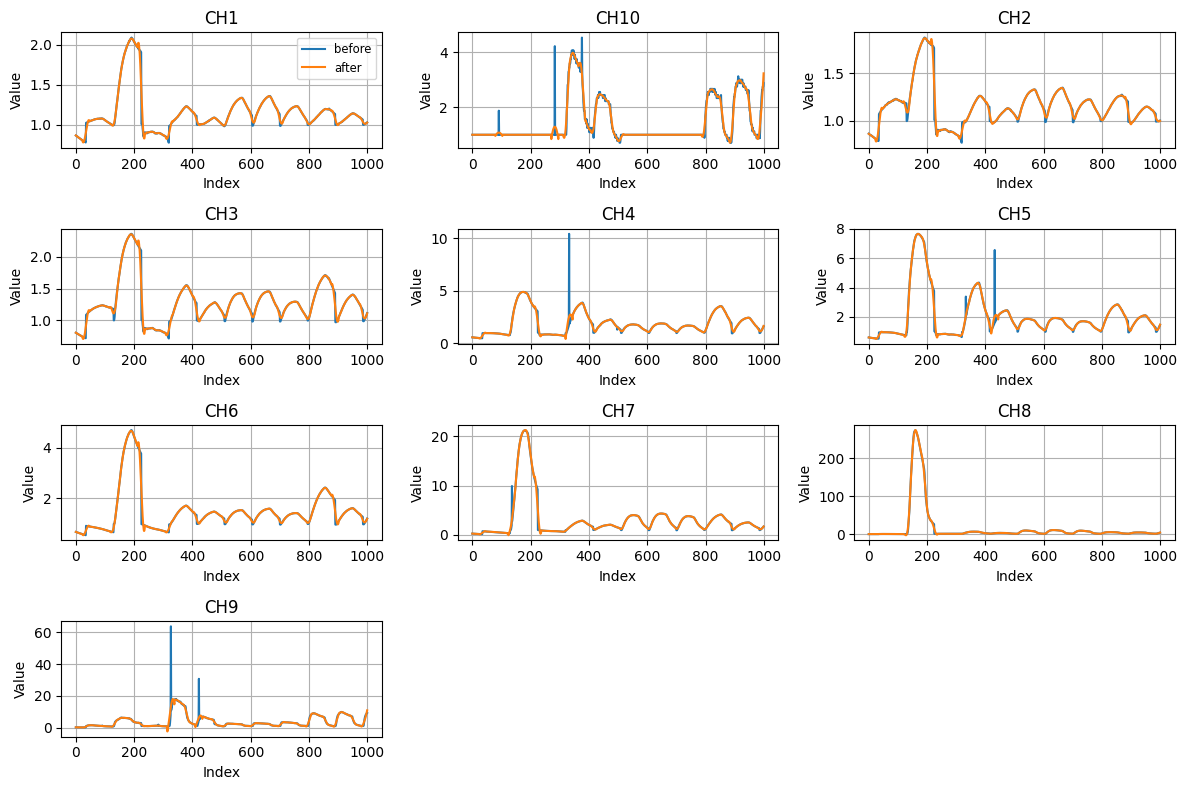

CPU times: user 1.18 s, sys: 8.78 ms, total: 1.19 s
Wall time: 1.2 s


In [55]:
%%time
start_idx = 5000
end_idx = 6000

# Ví dụ sử dụng
sub_df=df[start_idx:end_idx].copy()
sub_df_smooth = sub_df.copy()
sub_df_smooth[X_col] = sub_df[X_col].apply(SG_filter, w_size = 25)

# Plot kết quả làm mượt
plot_df_cols([sub_df, 
              sub_df_smooth], 
             X_col[:], 
             label_list=['before', 'after'])

## Kalman Filter
chưa áp dụng được

In [56]:
%%time
import numpy as np

def kalman_baseline_sensor(z, Q_base=1e-5, Q_drift=1e-6, R=1e-1, threshold=1, scale_R=100):
    """
    Kalman Filter 2D (baseline + drift) để tách baseline cảm biến khí khỏi tín hiệu có peak.

    Parameters
    ----------
    z : array-like
        Dữ liệu cảm biến 1D theo thời gian
    Q_base : float
        Process noise cho baseline (mức độ trôi nền)
    Q_drift : float
        Process noise cho tốc độ trôi (drift)
    R : float
        Measurement noise
    threshold : float
        Ngưỡng phát hiện peak (khi tín hiệu tăng quá nhanh)
    scale_R : float
        Hệ số tăng R khi gặp peak (giảm tin vào phép đo)
    """
    z = np.asarray(z, dtype=float)
    n = len(z)
    baseline_est = np.zeros_like(z)

    # --- Khởi tạo ---
    x = np.array([z[0], 0.0])  # [baseline, drift]
    P = np.eye(2)

    # Ma trận hệ thống
    F = np.array([[1, 1],
                  [0, 1]])
    H = np.array([[1, 0]])

    Q = np.array([[Q_base, 0],
                  [0, Q_drift]])

    for k in range(1, n):
        # --- Predict ---
        x_pred = F @ x
        P_pred = F @ P @ F.T + Q

        # --- Điều chỉnh R nếu tín hiệu tăng đột biến ---
        diff = abs(z[k] - x_pred[0])
        Rk = R * scale_R if diff > threshold else R

        # --- Update ---
        y = z[k] - H @ x_pred
        S = H @ P_pred @ H.T + Rk
        K = P_pred @ H.T / S
        x = x_pred + (K.flatten() * y)
        P = (np.eye(2) - K @ H) @ P_pred

        baseline_est[k] = x[0]

    return baseline_est

CPU times: user 11 µs, sys: 0 ns, total: 11 µs
Wall time: 16.2 µs


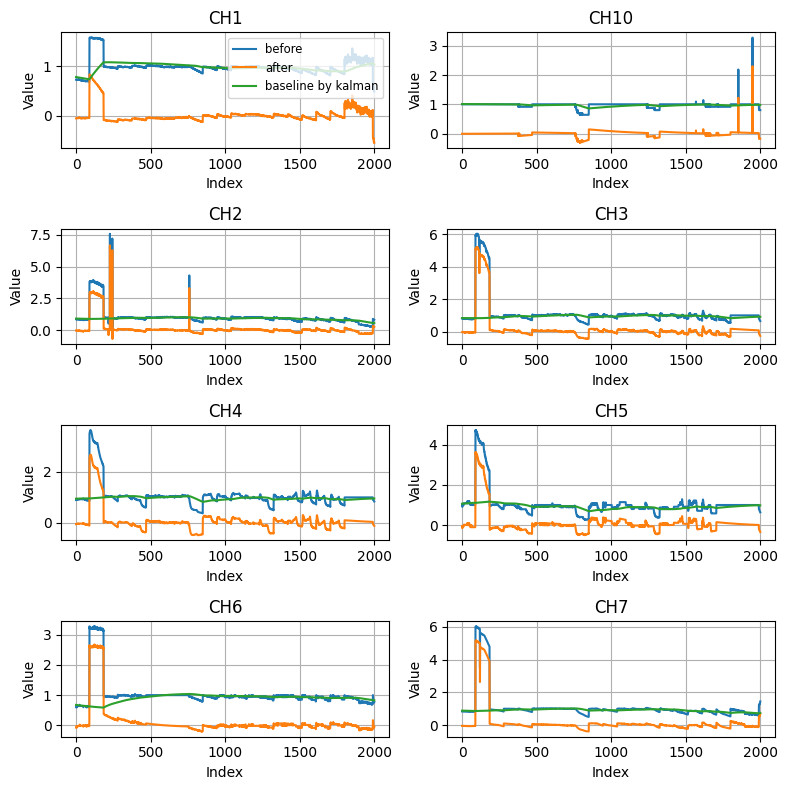

In [57]:
# --- Ước lượng baseline sử dụng Kalman filter---
df_kal=df.copy()
baseline_cols = df_kal[X_col].apply(kalman_baseline_sensor,
                                    Q_base=1e-7, Q_drift=1e-10, R=5e-1, threshold=1, scale_R=200)
df_kal[X_col] = df_kal[X_col] - baseline_cols

start_idx = 2000
end_idx = 4000
plot_df_cols([df[start_idx:end_idx], df_kal[start_idx:end_idx], baseline_cols[start_idx:end_idx]], 
             X_col[:8], 
             label_list=['before', 'after', 'baseline by kalman'])

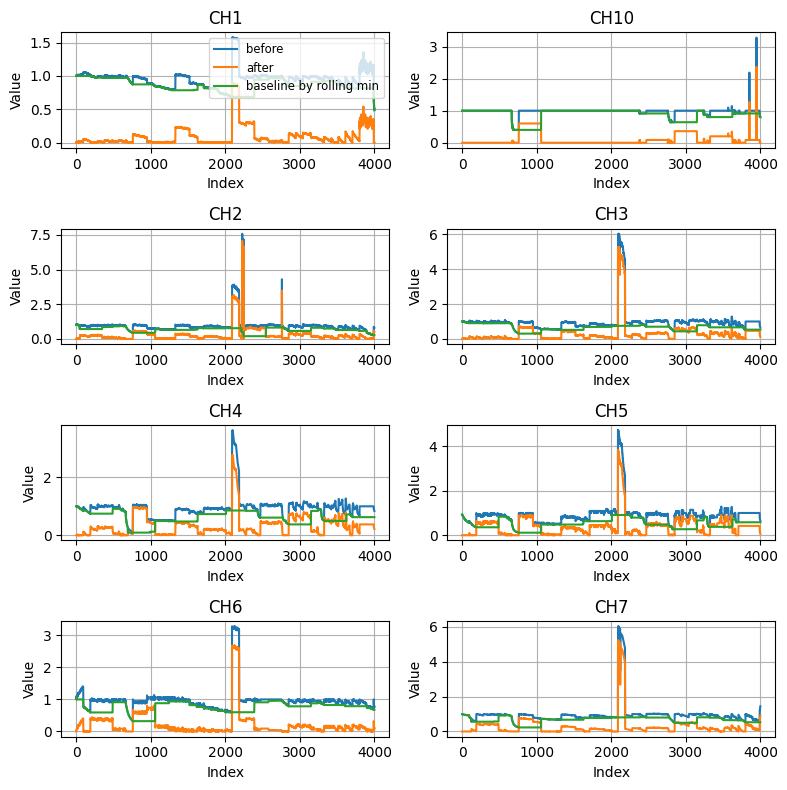

In [58]:
# --- Ước lượng baseline sử dụng rolling min---
df_kal=df.copy()
rolling_min = df_kal[X_col].rolling(window=300, center=False, min_periods=1).min()
df_kal[X_col] = df_kal[X_col] - rolling_min

start_idx = 0
end_idx = 4000
plot_df_cols([df[start_idx:end_idx], df_kal[start_idx:end_idx], rolling_min[start_idx:end_idx]], 
             X_col[:8], 
             label_list=['before', 'after', 'baseline by rolling min'])


## Preprocessing
- Bỏ những dòng null/ bị thiếu
- Bỏ những dòng không có khí nào
- Chia tách các lần đo/ các instance bằng cách gán cột 'Label'
- Bỏ những lần đo ngắn hơn 64s

In [59]:
# Tìm null -> abnormal thiếu nhiều cột -> tạm skip
missing_values = df.isnull().any(axis=1)
print("Các dòng dữ liệu lỗi:")
print(df[missing_values])

Các dòng dữ liệu lỗi:
       Acetone       Anomaly    CH1   CH10    CH2    CH3    CH4    CH5    CH6  \
0            0  Sensor drift  1.000  1.000  1.025  0.996  1.000  0.932  1.080   
1            0  Sensor drift  1.000  1.000  1.025  0.998  1.009  0.925  1.000   
2            0  Sensor drift  1.006  1.000  1.012  1.004  1.009  0.918  1.000   
3            0  Sensor drift  1.006  1.000  1.037  1.009  1.009  0.918  1.000   
4            0  Sensor drift  1.012  1.000  1.012  1.016  1.000  0.907  1.040   
...        ...           ...    ...    ...    ...    ...    ...    ...    ...   
49015     1000          None  1.046  1.250  1.150  1.400  1.000  1.000  1.056   
49016     1000          None  1.046  1.094  1.132  1.400  1.000  1.000  1.056   
49017     1000          None  1.046  1.094  1.150  1.333  0.969  1.000  1.056   
49018     1000          None  1.038  1.094  1.182  1.333  0.969  1.000  1.000   
49019     1000          None  1.038  1.094  1.118  1.333  0.969  1.000  1.000   

     

In [60]:
# Bỏ những dòng không có khí nào
def remove_empty_conc(df, filter_cols):
    # loại bỏ các hàng mà tất cả các cột filter đều bằng 0
    mask_all_zero = (df[filter_cols] == 0).all(axis=1)
    df_out = df.loc[~mask_all_zero]
    df_out = df_out.reset_index(drop=True)
    
    print(f"Previous remove empty shape: {df.shape}")
    print(f"After remove empty shape: {df_out.shape}")
    return df_out
    
# Ví dụ sử dụng
df2 = remove_empty_conc(df_smooth, y_col)
print(df2.shape)
df2.head()

Previous remove empty shape: (49020, 22)
After remove empty shape: (49020, 22)
(49020, 22)


,Acetone,Anomaly,CH1,CH10,CH2,CH3,CH4,CH5,CH6,CH7,...,Class,Date,Ethanol,Methanol,Ngay,STT,Sample,Thoigian,Time,is_normal
0,0,Sensor drift,1.003155,1.0,1.028670,0.996249,1.003502,0.933151,1.022455,0.991353,...,None,2023-10-30,50,0,NaT,1,1,None,07:45:08,0
1,0,Sensor drift,1.004092,1.0,1.027734,1.000113,1.003402,0.926220,1.027303,0.990606,...,None,2023-10-30,50,0,NaT,2,1,None,07:45:10,0
2,0,Sensor drift,1.004967,1.0,1.026807,1.003686,1.003253,0.919345,1.032283,0.989832,...,None,2023-10-30,50,0,NaT,3,1,None,07:45:12,0
3,0,Sensor drift,1.005779,1.0,1.025889,1.006968,1.003056,0.912526,1.037395,0.989033,...,None,2023-10-30,50,0,NaT,4,1,None,07:45:15,0
4,0,Sensor drift,1.006529,1.0,1.024981,1.009958,1.002811,0.905763,1.042640,0.988208,...,None,2023-10-30,50,0,NaT,5,1,None,07:45:17,0


In [61]:
def label_data(df):
    # Mỗi khi STT giảm so với dòng trước thì bắt đầu instance mới
    df['Label'] = (df['STT'] < df['STT'].shift()).cumsum() + 1

    # Đưa Label lên đầu
    df = df[['Label'] + [col for col in df.columns if col != 'Label']]
    
    return df

Drop total of 0 labels: []
Initial Label col have 516 values
Later Label col have 516 values


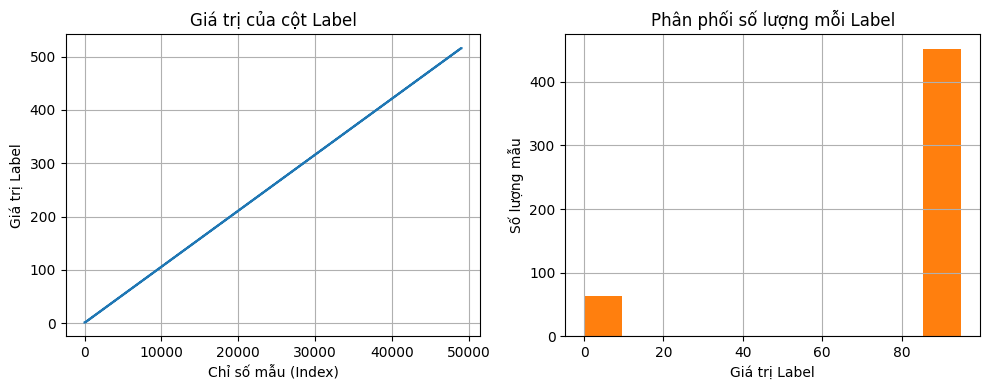

In [62]:
def drop_label_few(df, label_col, count_thres):
    # Drop Labels has fewer than 64 rows (ngắn hơn 64s)
    df = label_data(df)
    
    grouped = df.groupby('Label')
    labels_to_drop = []  
    
    # Iterate over each group
    for label, group in grouped:
        # Chdfk if the group has fewer than 64 rows
        if len(group) < 64:
            labels_to_drop.append(label)
            
    # Drop the rows with labels in labels_to_drop
    df_out = df[~df['Label'].isin(labels_to_drop)].reset_index(drop=True)
    print(f'Drop total of {len(labels_to_drop)} labels: {labels_to_drop}')
    
    # Relabeling
    df_out = label_data(df_out)
    df_out = df_out.reset_index(drop=True)
                               
    print(f"Initial Label col have {len(df['Label'].unique())} values")
    print(f"Later Label col have {len(df_out['Label'].unique())} values")
    return df_out

# Ví dụ dùng
df3 = drop_label_few(df2, label_col="Label", count_thres=6400)
grouped = df3.groupby('Label').count()['Thoigian']

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# --- Plot 1: Giá trị cột Label theo chỉ số ---
axes[0].plot(df3['Label'], color='tab:blue')
axes[0].set_title("Giá trị của cột Label")
axes[0].set_xlabel("Chỉ số mẫu (Index)")
axes[0].set_ylabel("Giá trị Label")
axes[0].grid(True)

# --- Plot 2: Phân phối độ dài của mỗi Label ---
grouped.hist(ax=axes[1], color='tab:orange')
axes[1].set_title("Phân phối số lượng mỗi Label")
axes[1].set_xlabel("Giá trị Label")
axes[1].set_ylabel("Số lượng mẫu")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Tách lại normal và abnormal để lưu riêng

In [63]:
abnormal_df = df3[df3['is_normal'] == 0].reset_index(drop=True)
normal_df = df3[df3['is_normal'] == 1].reset_index(drop=True)

print(normal_df.shape)
print(abnormal_df.shape)

(42940, 23)
(6080, 23)


## Split into 5 splits
- Tách data thành 5 phần nhỏ theo các lần đo (label)
- Chuẩn hóa (Normalization) từng phần bằng Min Max Scaler
- Các phần nhỏ không chứa label nào trùng nhau, có kich cỡ bằng nhau, được tách ngẫu nhiên

In [64]:
import random

def split_into_k_chunks(df, k, norm_cols):
    """
        Tách data thành 5 phần nhỏ theo các lần đo (label)
        Chuẩn hóa (Normalization) từng phần bằng Min Max Scaler
        Các phần nhỏ không chứa label nào trùng nhau, có kich cỡ bằng nhau, được tách ngẫu nhiên
    """
    numbers = df["Label"].unique().tolist()
    random.shuffle(numbers)
    
    # Chia thành 5 list con xấp xỉ bằng nhau
    k = 5
    chunk_size = len(numbers) // k
    remainder = len(numbers) % k
    
    subdatasets = []
    scaler = MinMaxScaler()
    
    start = 0
    for i in range(k):
        # Tìm sublist của label
        end = start + chunk_size + (1 if i < remainder else 0)
        sublist = numbers[start:end]
        start = end
    
        # Lọc ra dữ liệu của label trong sublist
        subset = df[df['Label'].isin(sublist)].copy().reset_index(drop=True)
        
        # Normalization - chuẩn hóa trên từng tập subdata/ tập split nhỏ    
        subset[norm_cols] = pd.DataFrame(scaler.fit_transform(subset[norm_cols]), columns=norm_cols)
    
        subdatasets.append(subset)
        print(f"Subdataset {i+1} ({len(sublist)} labels): {len(subset)} rows")
    return subdatasets

# Ví dụ sử dụng
# Tách dataframe thành 5 subdatasets tương ứng và Chuẩn hóa
subdatasets_normal = split_into_k_chunks(normal_df, k=5, norm_cols=X_col)
subdatasets_abnormal = split_into_k_chunks(abnormal_df, k=5, norm_cols=X_col)

Subdataset 1 (91 labels): 8645 rows
Subdataset 2 (91 labels): 8645 rows
Subdataset 3 (90 labels): 8550 rows
Subdataset 4 (90 labels): 8550 rows
Subdataset 5 (90 labels): 8550 rows
Subdataset 1 (13 labels): 1235 rows
Subdataset 2 (13 labels): 1235 rows
Subdataset 3 (13 labels): 1235 rows
Subdataset 4 (13 labels): 1235 rows
Subdataset 5 (12 labels): 1140 rows


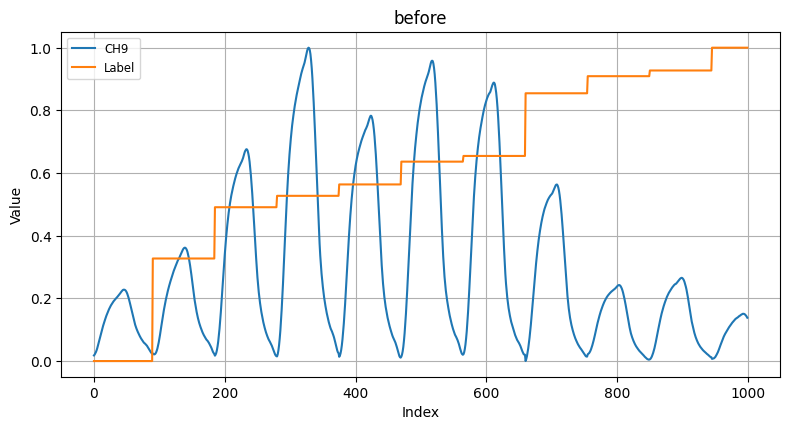

In [65]:
plot_dfs([subdatasets_normal[3][2000:3000]],
             X_col[9:13]+['Label'], 
             label_list=['before', 'after'])

## Augment 
**Thực hiện trên từng phần trong 5 phần:**
- Tăng cường bằng các bước nhảy lệch
- Chuyển sang cỡ ảnh 64x64 rồi lưu
- Mỗi lần đo/ instance/ group/ 1 ảnh gốc, sẽ được tăng cường thành 5 ảnh, lệch nhau step_size dòng

**Ví dụ:** 
- step_size = 10 => sẽ lấy bắt đầu từ index 0, 10, 20, 30, 40
- step_size = 20 => sẽ lấy bắt đầu từ index 0, 20, 40, 60, 80
- step_size = 25 => sẽ lấy bắt đầu từ index 0, 25, 50, 75, 100 (ảnh lấy từ 0 và 100 sẽ gần như trùng nhau)

**Mỗi ảnh sẽ gồm:**
- 64 cột (16 cột cảm biến x4),
- 64 dòng, mỗi dòng có Time(sdfonds) cách nhau 1 giây, tức cách nhau 100 dòng trong data gốc

In [66]:
%%time
def save_image(image_array, img_path):
    """save image as grayscale."""
    # Normalize image to range (0, 255)
    image = (image_array * 255).astype(np.uint8)
    # Save img
    image = Image.fromarray(image).convert("L")
    image.save(img_path)

# ==========================================================
# Mapping anomaly gốc -> dominant_abnormal chuẩn hóa
# ==========================================================

ANOMALY_MAP = {
    "Local noise": "Random Patch",
    "Random noise": "Noise",
    "Abrupt change": "Abrupt Change",
    "Sensor drift": "Signal Drift",
    "Sensor failure": "Sensor Failure",
    "Unknown gas": "Unknown Gas"
}


def generate_images(
    subdatasets,
    X_col,
    y_col,
    step_size=1,
    num_augments=1,
    out_dir="unaugmented"
):

    image_data = []

    for i, subdata in enumerate(subdatasets):

        folder_name = f"{out_dir}/split{i+1}"
        os.makedirs(folder_name, exist_ok=True)

        grouped = subdata.groupby("Label")
        print(
            "Number of groups:",
            len(grouped)
        )
        
        for label, group in grouped:

            for j in range(num_augments):

                start = j * step_size

                img_name = (
                    f"img_label{label}_aug{j}.png"
                    if num_augments > 1
                    else f"img_label{label}.png"
                )

                img_path = f"{folder_name}/{img_name}"

                # ======================================================
                # Tạo ảnh
                # ======================================================

                image = (
                    group.iloc[start:(64 + start)][X_col]
                    .to_numpy()
                )

                image = np.repeat(image, 8, axis=1)
                image = np.repeat(image, 2, axis=0)

                image = image[:128, :128]

                h, w = image.shape

                if h < 128 or w < 128:
                    image = np.pad(
                        image,
                        (
                            (0, max(0, 128 - h)),
                            (0, max(0, 128 - w))
                        ),
                        mode="constant"
                    )

                save_image(image, img_path)

                # ======================================================
                # Metadata cơ bản
                # ======================================================

                row_info = {
                    col: val
                    for col, val in zip(
                        y_col,
                        group.head(1)[y_col].values[0]
                    )
                }

                row_info["image_name"] = img_name
                row_info["split_number"] = i + 1

                # ======================================================
                # Dataset abnormal raw
                # ======================================================

                if "Anomaly" in group.columns:

                    original_anomaly = (
                        group["Anomaly"]
                        .iloc[0]
                    )

                    dominant_abnormal = ANOMALY_MAP.get(
                        original_anomaly,
                        original_anomaly
                    )

                    row_info["dominant_abnormal"] = (
                        dominant_abnormal
                    )

                    row_info["severity"] = np.nan

                    row_info["abnormal_detail"] = str({
                        dominant_abnormal: 1.0
                    })

                    row_info["is_normal"] = 0

                # ======================================================
                # Dataset normal
                # ======================================================

                else:

                    row_info["dominant_abnormal"] = np.nan
                    row_info["severity"] = 0.0
                    row_info["abnormal_detail"] = np.nan
                    row_info["is_normal"] = 1

                image_data.append(row_info)

    # ==========================================================
    # Save CSV
    # ==========================================================

    image_data_df = pd.DataFrame(image_data)

    csv_path = f"{out_dir}/image_labels.csv"

    image_data_df.to_csv(
        csv_path,
        index=False
    )

    print(f"Saved: {csv_path}")

    return image_data_df
    
# ví dụ sử dụng 
result = generate_images(subdatasets_normal, X_col, y_col,
               step_size=2,
               num_augments=2,
               out_dir="augmented")

Number of groups: 91
Number of groups: 91
Number of groups: 90
Number of groups: 90
Number of groups: 90
Saved: augmented/image_labels.csv
CPU times: user 1.99 s, sys: 121 ms, total: 2.11 s
Wall time: 2.11 s


# Toàn bộ quy trình 
(xử lý và lọc nhiễu, tách thành ảnh, tăng cường dữ liệu và lưu lại)

In [67]:
%%time
def complete_pipeline(df_ori, X_col, y_col, chunk_numb = 5, aug_step_size = 2, aug_times = 2):
    df = df_ori.copy()
    
    # SG filter smooth
    df[X_col] = df[X_col].apply(SG_filter)

    # Filter out rows with no gas or too few data (<64s)
    # df = remove_empty_conc(df, y_col)
    df = drop_label_few(df, label_col="Label", count_thres=6400)

    # Split normal and abnormal 
    normal_df = df[df['is_normal'] == 1].reset_index(drop=True)
    abnormal_df = df[df['is_normal'] == 0].reset_index(drop=True)

    # Split data into chunks
    subdatasets_normal = split_into_k_chunks(normal_df, k=chunk_numb, norm_cols=X_col)
    subdatasets_abnormal = split_into_k_chunks(abnormal_df, k=chunk_numb, norm_cols=X_col)
    
    # Augment each chunk, normalize, cut into images, and save
    augmented_df = generate_images(subdatasets_normal, X_col, y_col,
                                   step_size=aug_step_size,
                                   num_augments=aug_times,
                                   out_dir="augmented")
    print(augmented_df.groupby('split_number').count())

    # Normalize, cut into images, and save
    unaugmented_df = generate_images(subdatasets_normal, X_col, y_col,
                                     step_size=aug_step_size,
                                     num_augments=1,
                                     out_dir="unaugment")
    print(unaugmented_df.groupby('split_number').count())

    # ------------------------
    # ABNORMAL AUGMENTED
    # ------------------------
    ab_augmented_df = generate_images(subdatasets_abnormal, X_col, y_col,
                                     step_size=aug_step_size,
                                     num_augments=aug_times,
                                     out_dir="augmented_abnormal_raw")

    print("Augmented abnormal:")
    print(ab_augmented_df.groupby('split_number').count())


# Xử lý dữ liệu
complete_pipeline(df, X_col, y_col)

Drop total of 0 labels: []
Initial Label col have 516 values
Later Label col have 516 values
Subdataset 1 (91 labels): 8645 rows
Subdataset 2 (91 labels): 8645 rows
Subdataset 3 (90 labels): 8550 rows
Subdataset 4 (90 labels): 8550 rows
Subdataset 5 (90 labels): 8550 rows
Subdataset 1 (13 labels): 1235 rows
Subdataset 2 (13 labels): 1235 rows
Subdataset 3 (13 labels): 1235 rows
Subdataset 4 (13 labels): 1235 rows
Subdataset 5 (12 labels): 1140 rows
Number of groups: 91
Number of groups: 91
Number of groups: 90
Number of groups: 90
Number of groups: 90
Saved: augmented/image_labels.csv
              Ethanol  Acetone  Methanol  image_name  dominant_abnormal  \
split_number                                                              
1                 182      182       182         182                  0   
2                 182      182       182         182                  0   
3                 180      180       180         180                  0   
4                 180      180   

# Ví dụ đọc data thành tập train và test

In [68]:
# Đọc file csv chứa thông tin về ảnh (nồng độ, tên ảnh, split tương ứng)
folder = "augmented_abnormal_raw" 
# folder = "unaugment" 
result = pd.read_csv(f'/kaggle/working/{folder}/image_labels.csv')
result.head()

,Ethanol,Acetone,Methanol,image_name,split_number,dominant_abnormal,severity,abnormal_detail,is_normal
0,50,0,0,img_label1_aug0.png,1,Signal Drift,NaN,{'Signal Drift': 1.0},0
1,50,0,0,img_label1_aug1.png,1,Signal Drift,NaN,{'Signal Drift': 1.0},0
2,100,0,0,img_label2_aug0.png,1,Signal Drift,NaN,{'Signal Drift': 1.0},0
3,100,0,0,img_label2_aug1.png,1,Signal Drift,NaN,{'Signal Drift': 1.0},0
4,0,1500,0,img_label13_aug0.png,1,Noise,NaN,{'Noise': 1.0},0


In [69]:
# Hàm đọc ảnh từ những split cho vào
# Trả về ảnh và nhãn tương ứng dưới dạng: ma trận [số ảnh, 64, 64, 1] và ma trận [số ảnh,2]
def read_image(path):
    """
    Đọc ảnh grayscale và trả về numpy array (giá trị 0–1)
    """
    img = Image.open(path).convert('L')
    arr = np.array(img).astype(np.float32) / 255.0
    return arr

def read_img_from_splits(df, split_list, folder="augmented"):
    # Chỉ lấy các dòng thuộc list split đã chọn
    df_part = df[df['split_number'].isin(split_list)]
    images = []

    # Lặp qua từng hàng trong dataframe để đọc ảnh và lấy nhãn tương ứng 
    for index, row in df_part.iterrows():
        img_path = folder + '/split' + str(row['split_number']) + '/' + str(row['image_name'])
        img = read_image(img_path)
        # img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # Đọc ảnh xám
        # img = np.array(img).astype('float32') / 255.0  # Chuẩn hóa dữ liệu ảnh
        images.append(img)

    # Chuyển đổi danh sách thành numpy arrays
    df_part.loc[:,["Image"]] = images
    images = np.array(images)
    
    return images, df_part[y_col], df_part

In [70]:
# Xác định tập train và test sẽ gồm những split nào trong 5 split
# Chỉ cần điền những split trong tập test, tập train sẽ tự bao gồm những split còn lại
# VD: split_test = [3,5] thì split_train = [1,2,4]
split_test = [4, 2]

split_train = [i for i in range(1,6) if i not in split_test] 
print("Những split sẽ thuộc tập train là: ", split_train)
print("Những split sẽ thuộc tập test là: ", split_test)

Những split sẽ thuộc tập train là:  [1, 3, 5]
Những split sẽ thuộc tập test là:  [4, 2]


In [71]:
%%time
# Sử dụng hàm đọc ảnh từ thư mục các split tương ứng
X_train, y_train, df_train = read_img_from_splits(result, split_train, folder=folder)
X_test, y_test, df_test = read_img_from_splits(result, split_test, folder=folder)

print(f'X_train shape: {X_train.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_test shape: {y_test.shape}')
df_train

X_train shape: (76, 128, 128)
y_train shape: (76, 3)
X_test shape: (52, 128, 128)
y_test shape: (52, 3)
CPU times: user 58.6 ms, sys: 10 ms, total: 68.7 ms
Wall time: 67.1 ms


,Ethanol,Acetone,Methanol,image_name,split_number,dominant_abnormal,severity,abnormal_detail,is_normal,Image
0,50,0,0,img_label1_aug0.png,1,Signal Drift,NaN,{'Signal Drift': 1.0},0,"[[0.75686276, 0.75686276, 0.75686276, 0.756862..."
1,50,0,0,img_label1_aug1.png,1,Signal Drift,NaN,{'Signal Drift': 1.0},0,"[[0.7529412, 0.7529412, 0.7529412, 0.7529412, ..."
2,100,0,0,img_label2_aug0.png,1,Signal Drift,NaN,{'Signal Drift': 1.0},0,"[[0.7176471, 0.7176471, 0.7176471, 0.7176471, ..."
3,100,0,0,img_label2_aug1.png,1,Signal Drift,NaN,{'Signal Drift': 1.0},0,"[[0.7176471, 0.7176471, 0.7176471, 0.7176471, ..."
4,0,1500,0,img_label13_aug0.png,1,Noise,NaN,{'Noise': 1.0},0,"[[0.05882353, 0.05882353, 0.05882353, 0.058823..."
...,...,...,...,...,...,...,...,...,...,...
123,0,500,3000,img_label47_aug1.png,5,Signal Drift,NaN,{'Signal Drift': 1.0},0,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.16..."
124,0,4500,200,img_label52_aug0.png,5,Signal Drift,NaN,{'Signal Drift': 1.0},0,"[[0.77254903, 0.77254903, 0.77254903, 0.772549..."
125,0,4500,200,img_label52_aug1.png,5,Signal Drift,NaN,{'Signal Drift': 1.0},0,"[[0.7764706, 0.7764706, 0.7764706, 0.7764706, ..."
126,NH3_50_H2S_10,0,0,img_label63_aug0.png,5,Unknown Gas,NaN,{'Unknown Gas': 1.0},0,"[[0.8862745, 0.8862745, 0.8862745, 0.8862745, ..."


# Tạo bất thường (bỏ)

## Các loại bất thường

In [72]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import cv2

# --- Các hàm tạo bất thường cơ bản ---
def add_noise(img, severity=0.3):
    """
    Nhiễu Gaussian nhưng khác nhau theo từng sensor (cột)
    """
    H, W = img.shape[:2]
    
    # mỗi sensor có noise khác nhau
    sensor_std = np.random.uniform(0.01, severity, W)
    noise = np.random.randn(H, W) * sensor_std
    
    return np.clip(img + noise, 0, 1)
def add_signal_drift(img, direction='vertical', severity=0.3):
    """
    Drift theo thời gian (chiều H) – giống aging cảm biến
    """
    H, W = img.shape[:2]
    
    t = np.linspace(0, 1, H)
    
    # drift không tuyến tính (thực tế hơn)
    drift = (t ** 1.5) * severity  
    drift = drift[:, np.newaxis]
    
    return np.clip(img + drift, 0, 1)
def add_random_patch(img, size_ratio=0.1, severity=0.8):
    """
    Một vùng nhỏ bị nhiễu mạnh (sensor lỗi cục bộ hoặc nhiễu môi trường)
    """
    H, W = img.shape[:2]
    
    patch_H = int(H * size_ratio)
    patch_W = int(W * size_ratio)
    
    y = np.random.randint(0, H - patch_H)
    x = np.random.randint(0, W - patch_W)
    
    direction = np.random.choice([-1, 1])
    
    img_new = img.copy()
    img_new[y:y+patch_H, x:x+patch_W] += severity * direction
    
    return np.clip(img_new, 0, 1)
def add_abrupt_change(img, severity=0.4):
    """
    Tín hiệu thay đổi đột ngột (ví dụ: thay đổi khí hoặc lỗi hệ thống)
    """
    H, W = img.shape[:2]
    
    cut = np.random.randint(H // 4, 3 * H // 4)
    direction = np.random.choice([-1, 1])
    
    magnitude = severity * direction
    
    # tạo transition mượt
    transition_len = int(H * 0.1)
    ramp = np.zeros(H)
    
    smooth = np.linspace(0, magnitude, transition_len)
    
    ramp[cut:cut+transition_len] = smooth[:max(0, H - cut)]
    
    if cut + transition_len < H:
        ramp[cut+transition_len:] = magnitude
    
    ramp = ramp[:, np.newaxis]
    
    return np.clip(img + ramp, 0, 1)
def add_sensor_failure(img, severity=0.1):
    H, W = img.shape[:2]
    
    num_fail = int(W * severity)  # dùng severity thay ratio
    fail_idx = np.random.choice(W, num_fail, replace=False)
    
    img_new = img.copy()
    
    for i in fail_idx:
        mode = np.random.choice(['dead', 'stuck'])
        
        if mode == 'dead':
            img_new[:, i] = 0
        else:
            img_new[:, i] = img_new[0, i]
    
    return np.clip(img_new, 0, 1)

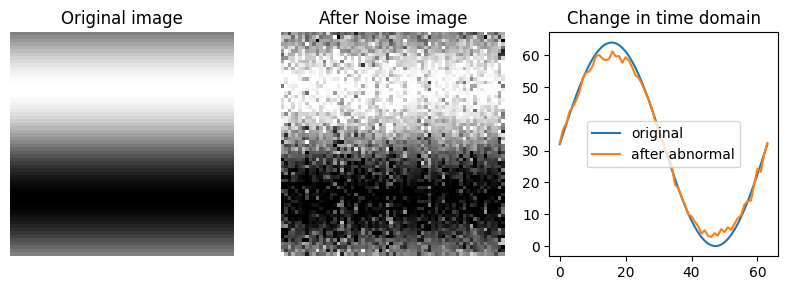

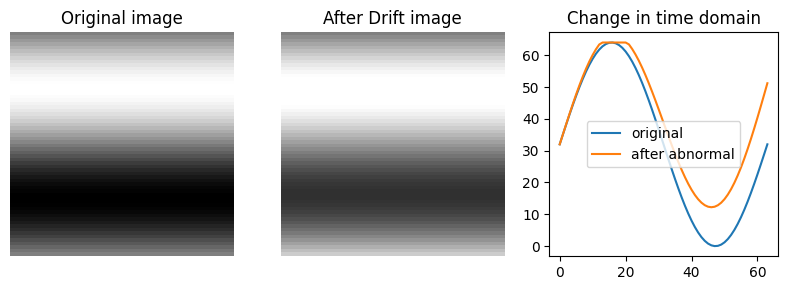

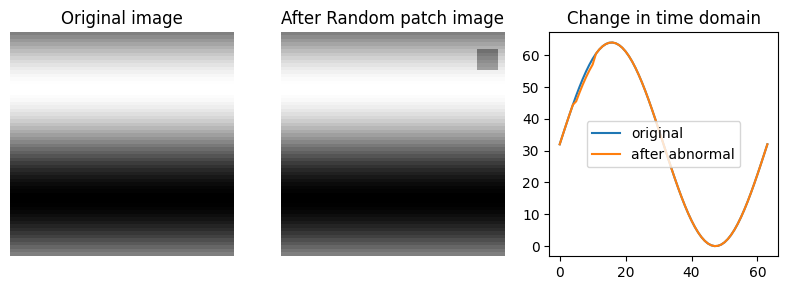

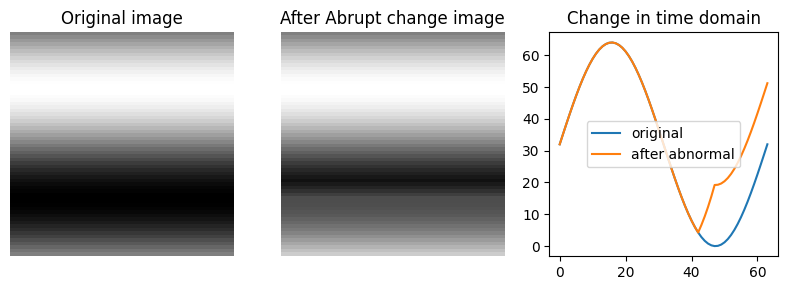

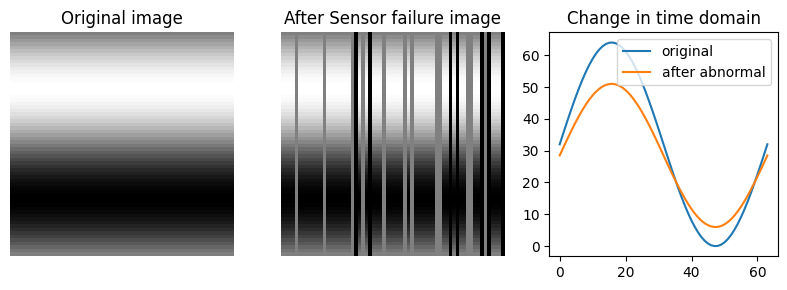

In [73]:
def visualize_abnormal_change(ab_func, ab_name, severity, scale=True):
    vmin=0 if scale else None
    vmax=1 if scale else None
    
    # ảnh
    x = np.linspace(0, 2*np.pi, 64)
    sin_wave = (np.sin(x) + 1) / 2
    img = np.tile(sin_wave[:, None], (1, 64))
    
    img_ab = ab_func(img, severity=severity)

    # visualize
    plt.figure(figsize=(8,3))
    if scale:
        plt.subplot(1,3,1)
        plt.imshow(img, cmap='gray', vmin=vmin, vmax=vmax); plt.title("Original image"); plt.axis("off")
    plt.subplot(1,3,2)
    plt.imshow(img_ab, cmap='gray', vmin=vmin, vmax=vmax); plt.title(f"After {ab_name} image"); plt.axis("off")
    
    plt.subplot(1,3,3)
    plt.plot(img.sum(axis=1), label='original')
    plt.plot(img_ab.sum(axis=1), label='after abnormal'); plt.title("Change in time domain")

    plt.tight_layout()
    plt.legend()
    plt.show()

severity = 0.3
scale = True # Scale lại ảnh về khoảng 0 1 để thấy rõ sự thay đổi theo severity
visualize_abnormal_change(add_noise, "Noise", severity, scale=scale)
visualize_abnormal_change(add_signal_drift, "Drift", severity, scale=scale)
visualize_abnormal_change(add_random_patch, "Random patch", severity, scale=scale)
visualize_abnormal_change(add_abrupt_change, "Abrupt change", severity, scale=scale)
visualize_abnormal_change(add_sensor_failure, "Sensor failure", severity, scale=scale)

## Áp bất thường lên ảnh

In [74]:
def apply_abnormal(img, label, severity_range=(0.1, 0.3), show=True):
    """
    Mỗi abnormal được áp với severity ngẫu nhiên.
    Trả về:
        img_ab
        severity_dict
        dominant_abnormal
    """

    img_ab = img.copy()

    methods = {
        "Noise": lambda x, s: add_noise(x, s),
        "Signal Drift": lambda x, s: add_signal_drift(
            x,
            random.choice(['horizontal', 'vertical']),
            s
        ),
        "Random Patch": lambda x, s: add_random_patch(
            x,
            size_ratio=0.1 + s * 0.1,
            severity=s
        ),
        "Abrupt Change": lambda x, s: add_abrupt_change(x, s),    
        "Sensor Failure": lambda x, s: add_sensor_failure(
            x,
            severity=s
        ),
    }

    chosen_methods = random.sample(
        list(methods.items()),
        random.randint(1, len(methods))
    )

    severity_dict = {}

    for name, fn in chosen_methods:

        severity = np.random.uniform(
            severity_range[0],
            severity_range[1]
        )

        severity_dict[name] = float(severity)

        img_ab = fn(img_ab, severity)
        img_ab = np.clip(img_ab, 0, 1)

    dominant_abnormal = max(
        severity_dict,
        key=severity_dict.get
    )

    if show:

        fig, axes = plt.subplots(1, 2, figsize=(10, 4))

        gas_info = " | ".join(
            [f"{gas}: {float(value):.2f}"
             for gas, value in label.items()]
        )

        axes[0].imshow(
            img.squeeze(),
            cmap='gray',
            vmin=0,
            vmax=1
        )
        axes[0].set_title(f"Original\n{gas_info}")
        axes[0].axis("off")

        severity_text = "\n".join(
            [
                f"{k}: {v:.3f}"
                for k, v in severity_dict.items()
            ]
        )

        axes[1].imshow(
            img_ab.squeeze(),
            cmap='gray',
            vmin=0,
            vmax=1
        )

        axes[1].set_title(
            f"Dominant: {dominant_abnormal}\n{severity_text}"
        )

        axes[1].axis("off")

        plt.tight_layout()
        plt.show()

    return img_ab, severity_dict, dominant_abnormal
    
# --- Hàm chính ---
def generate_anomaly_from_df(df, 
                             anomaly_ratio=0.2, 
                             random_seed=42):
    """
    Tạo bất thường từ DataFrame chứa ảnh gốc.
    This notebook originally belong to huong.nguyenthu4@hust.edu.vn
    
    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame chứa ít nhất 2 cột:
            - 'Image': numpy array (H, W)
            - 'image_name': string
    anomaly_ratio : float
        Tỉ lệ số ảnh sẽ được chọn để tạo bất thường (0–1)
    random_seed : int | None
        Đặt seed để tái lập kết quả

    Returns:
    --------
    df_out : pd.DataFrame
        DataFrame chứa cả ảnh bình thường và bất thường,
        có thêm cột 'is_normal' (1=bình thường, 0=bất thường),
        và ảnh bất thường có tên thêm "_ab" vào trước ".png".
    """
    if random_seed is not None:
        np.random.seed(random_seed)
        random.seed(random_seed)

    df = df.copy()

    # Đánh nhãn ảnh gốc
    df['is_normal'] = 1
    df['severity'] = 0

    # Số ảnh bất thường cần tạo
    n_anomalies = int(len(df) * anomaly_ratio)
    chosen_idx = random.sample(range(len(df)), n_anomalies)

    anomaly_rows = []

    # Duyệt từng ảnh được chọn để tạo bất thường
    for idx in chosen_idx:
    
        row = df.iloc[idx]
    
        img = row['Image']
        label = row[y_col]
    
        show = np.random.uniform() < 0.01
    
        img_ab, severity_dict, dominant_abnormal = apply_abnormal(
            img,
            label=label,
            severity_range=(0.01, 0.1),
            show=show
        )
    
        new_row = row.copy()
    
        new_row['Image'] = img_ab
    
        new_row['image_name'] = (
            row['image_name']
            .replace('.png', '_ab.png')
        )
    
        new_row['is_normal'] = 0
    
        # abnormal mạnh nhất
        new_row['dominant_abnormal'] = dominant_abnormal
    
        # severity của abnormal mạnh nhất
        new_row['severity'] = severity_dict[dominant_abnormal]
    
        # lưu toàn bộ severity
        new_row['abnormal_detail'] = severity_dict
    
        anomaly_rows.append(new_row)
        
    # Ghép và sắp xếp
    df_ab = pd.DataFrame(anomaly_rows)
    df_out = pd.concat([df, df_ab], ignore_index=True)
    df_out = df_out.sort_values(by='image_name').reset_index(drop=True)

    return df_out

Split 1: loaded 182 normal images. 

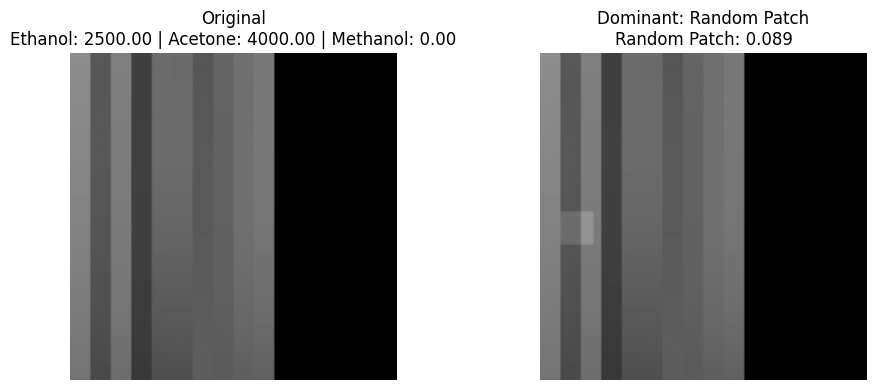

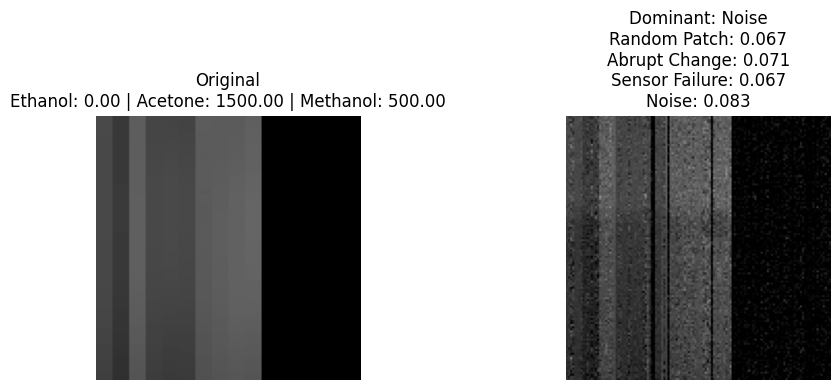

Generated anomalies → total 364 images
Split 2: loaded 182 normal images. 

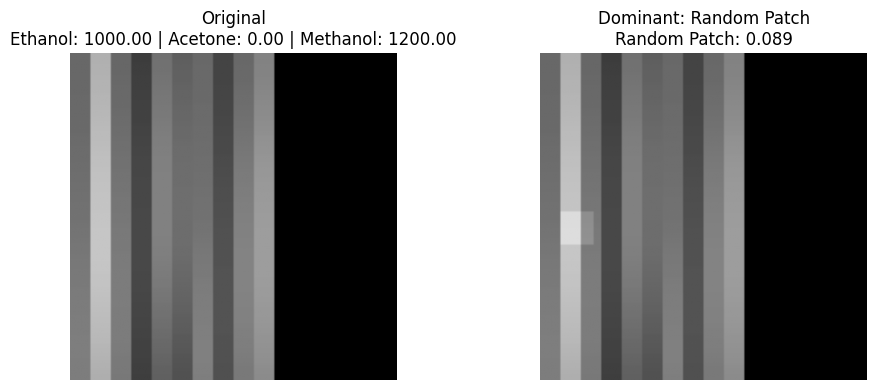

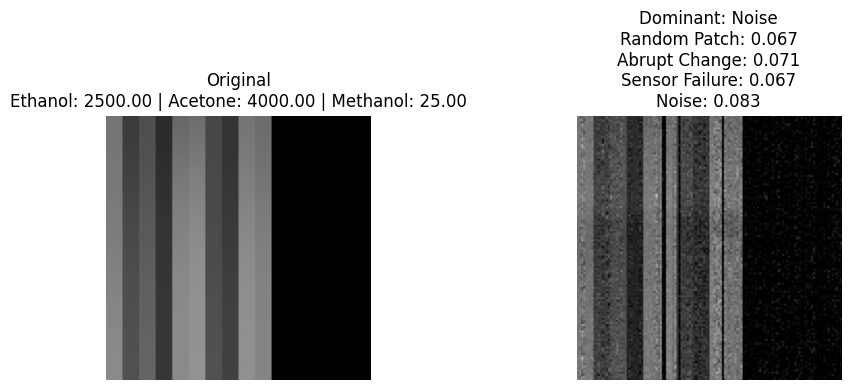

Generated anomalies → total 364 images
Split 3: loaded 180 normal images. 

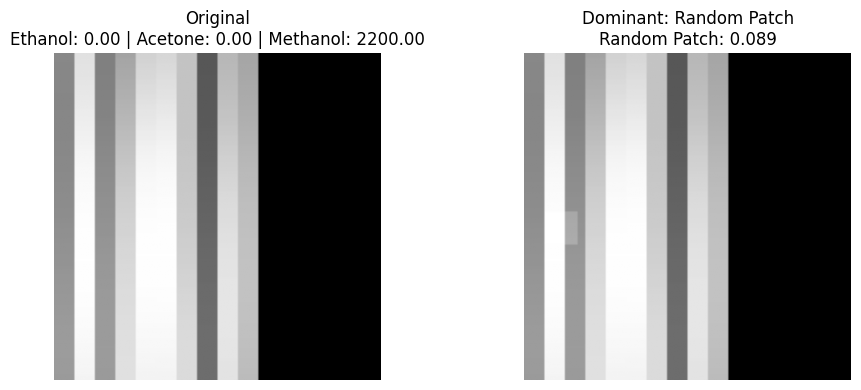

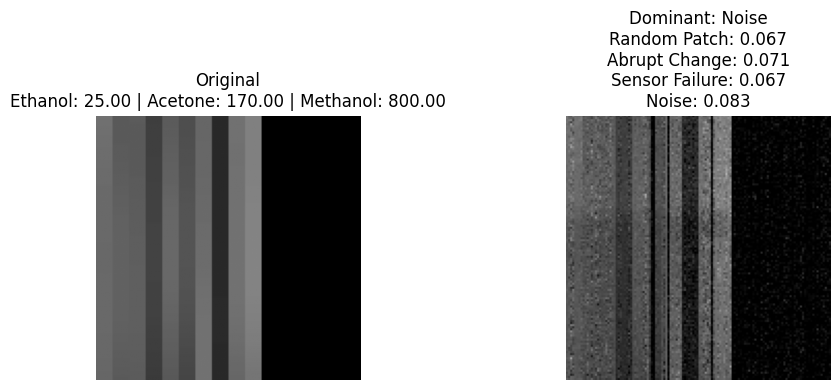

Generated anomalies → total 360 images
Split 4: loaded 180 normal images. 

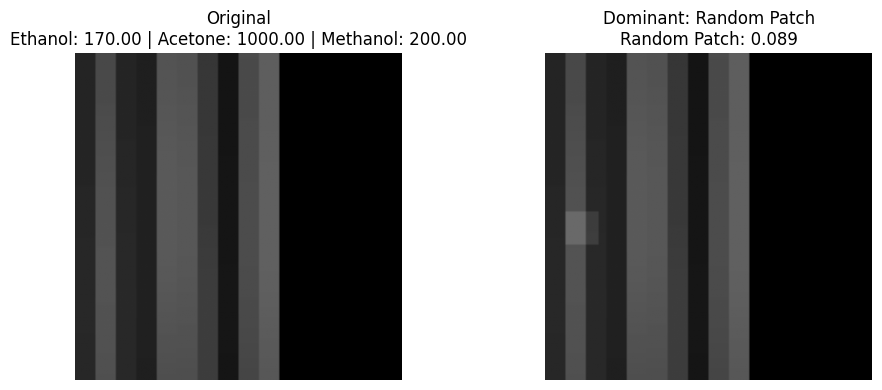

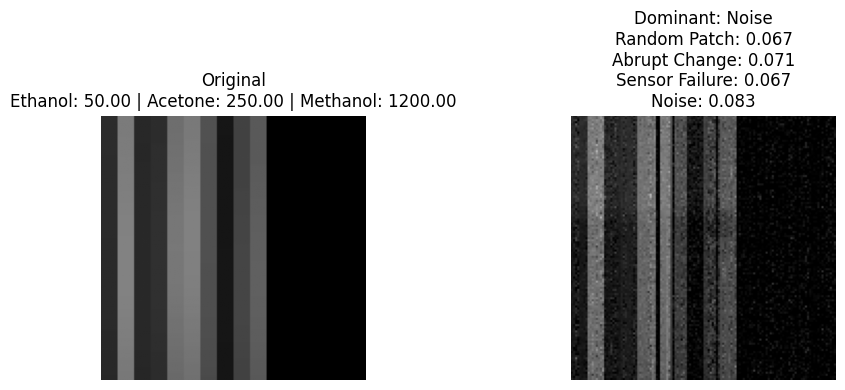

Generated anomalies → total 360 images
Split 5: loaded 180 normal images. 

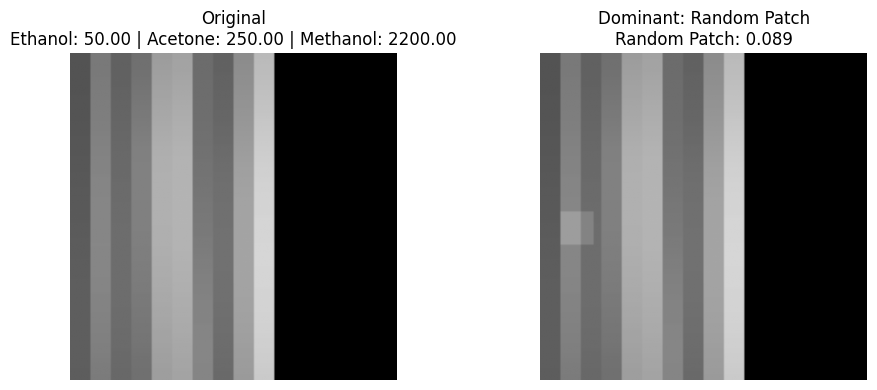

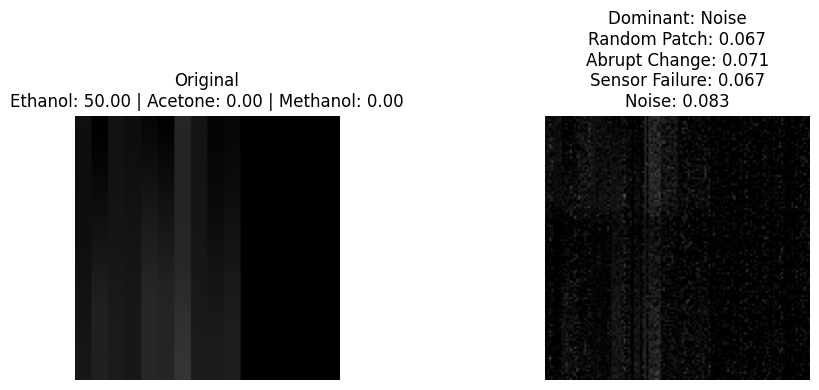

Generated anomalies → total 360 images
✅ Done: Generated augmented abnormal dataset.


,Ethanol,Acetone,Methanol,image_name,split_number,dominant_abnormal,severity,abnormal_detail,is_normal
0,0,1500,0,img_label105_aug0.png,1,NaN,0.000000,{None: 1.0},1
1,0,1500,0,img_label105_aug0_ab.png,1,Signal Drift,0.096618,"{'Random Patch': 0.0871832530970627, 'Abrupt C...",0
2,0,1500,0,img_label105_aug1.png,1,NaN,0.000000,{None: 1.0},1
3,0,1500,0,img_label105_aug1_ab.png,1,Abrupt Change,0.092939,{'Abrupt Change': 0.09293938053370843},0
4,0,170,0,img_label110_aug0.png,1,NaN,0.000000,{None: 1.0},1
...,...,...,...,...,...,...,...,...,...
1803,0,500,0,img_label96_aug1_ab.png,5,Sensor Failure,0.065963,"{'Random Patch': 0.01361279418164259, 'Sensor ...",0
1804,0,250,0,img_label98_aug0.png,5,NaN,0.000000,{None: 1.0},1
1805,0,250,0,img_label98_aug0_ab.png,5,Signal Drift,0.094933,{'Signal Drift': 0.09493281275882419},0
1806,0,250,0,img_label98_aug1.png,5,NaN,0.000000,{None: 1.0},1


In [75]:
import pandas as pd

anomaly_ratio = 1
# severity_lvs = [0.05, 0.1, 0.15]
source_folder = "augmented"
out_dir = "augmented_abnormal_gen"

os.makedirs(out_dir, exist_ok=True)
df_result = pd.read_csv(f"/kaggle/working/{source_folder}/image_labels.csv")
df_out = pd.DataFrame()

# Đọc các split của dữ liệu đã tăng cường, 
for split in range(1, 6):
    folder_name = f"{out_dir}/split{split}"
    os.makedirs(folder_name, exist_ok=True)

    # tạo bất thường cho từng split, 
    _, _, df_split = read_img_from_splits(df_result, [split], folder=source_folder)
    print(f"Split {split}: loaded {len(df_split)} normal images. ", end='')

    df_ab = generate_anomaly_from_df(df_split, anomaly_ratio=anomaly_ratio, random_seed=42)
    print(f"Generated anomalies → total {len(df_ab)} images")

    # lưu vào folder riêng với cấu trúc tương tự
    for _, row in df_ab.iterrows():
        img_name = row["image_name"]
        img_path = f"{folder_name}/{img_name}"
        img = row["Image"]
        save_image(img, img_path)
    
    df_out = pd.concat([df_out, df_ab.loc[:, df_ab.columns != "Image"]], ignore_index=True)
# Lưu metadata
df_out.to_csv(f"{out_dir}/image_labels.csv", index=False)

print("✅ Done: Generated augmented abnormal dataset.")
df_out

<Axes: >

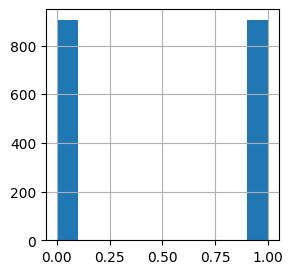

In [76]:
#Với mỗi ảnh thường, tạo một ảnh bất thường
df_out['is_normal'].hist(figsize=(3,3))

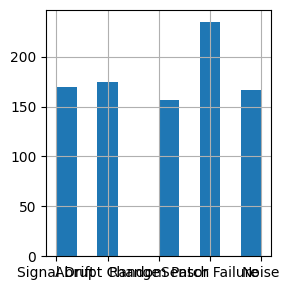

In [77]:
df_out['dominant_abnormal'].hist(figsize=(3,3))
plt.tight_layout()
plt.show()

In [78]:
import shutil

# Nén toàn bộ thư mục /kaggle/working thành file working.zip
shutil.make_archive('/kaggle/working/working', 'zip', '/kaggle/working')

'/kaggle/working/working.zip'